# 02. 상담 예제 1 — "카드가 안 긁히는데 어떻게 해야 하나요?" (clarification loop)

첫 번째 상담 예제입니다. 고객 문의에 **구체 정보가 없어서**, agent가 D5(정보 충분성)에서 `need_clarification`을 판정하고 **되묻는 질문을 생성 -> 고객 답변 수신 -> 재판정**하는 recursive loop를 돕니다.

예상 경로:
```
D1(guardrail) -> D2(routing) -> D5(need_clarification) -> 되묻기/답변 -> D5(info_sufficient)
-> D3(tool 선택) -> tool 성공 -> D6(goal_met) -> 요약 -> D7(no_risk) -> D4(resolve) -> 최종 응답
```

같은 질문을 **① Haiku 판단**으로, **② strands-decider 판단**으로 각각 실행하며 STEP별 출력을 관찰하고, 마지막에 수행시간을 비교합니다. (응답 생성은 양쪽 모두 Sonnet 4.5 — 차이는 판단 계층뿐)

In [1]:
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # ws_common 경로 (repo 내 상대 위치)
import ws_common as W
graphs, client = W.make_graphs()
sc = W.SCENARIOS[1]
print("시나리오:", sc["title"])
print("고객 질문:", sc["question"])
print("script(실습 재현용 사전 설정):", sc["script"])

시나리오: 모호한 문의 -> clarification loop
고객 질문: 카드가 안 긁히는데 어떻게 해야 하나요?
script(실습 재현용 사전 설정): {'vague': True, 'clarify_reply': '어제부터 오프라인 매장 단말기에서만 승인이 거절돼요. 관련 정보: Visa 체크카드(끝자리 7712), 마지막 시도 2026-10-27 TechMart 강남점, 금액 45,000원입니다.', 'no_info_reply': '지금 알려드릴 수 있는 정보는 그게 전부예요.', 'tool_outcomes': ['success'], 'risk_flag': False, 'kyc_result': None}


## 전체 workflow에서 이 시나리오의 위치

이번 시나리오가 지나는 경로(빨간 테두리): 접수 심사 -> 업무 분류 -> **되묻기 loop(clarify_gate <-> ask_clarify)** -> tool 1회 성공 -> 요약 -> 리스크 이상 없음 -> 종결. KYC sub-flow와 give_up 경로는 이번에는 지나가지 않습니다.

배정 상담팀(빨간 표시): **cards(카드 발급/배송)** — 카드 오작동 문의이므로 cards 팀 tool(card_troubleshoot)로 처리됩니다.
> 참고: 이 다이어그램은 실행되는 LangGraph에서 자동 생성된 것이 아니라, `ws_common.py`의 한글 캡션 사전(`KO_NODES`/`KO_EDGES`)을 노드 이름 기준으로 그린 **시각화 전용 그림**입니다 (상세 설명: `[KR]_01_build_agent.ipynb` 참조).


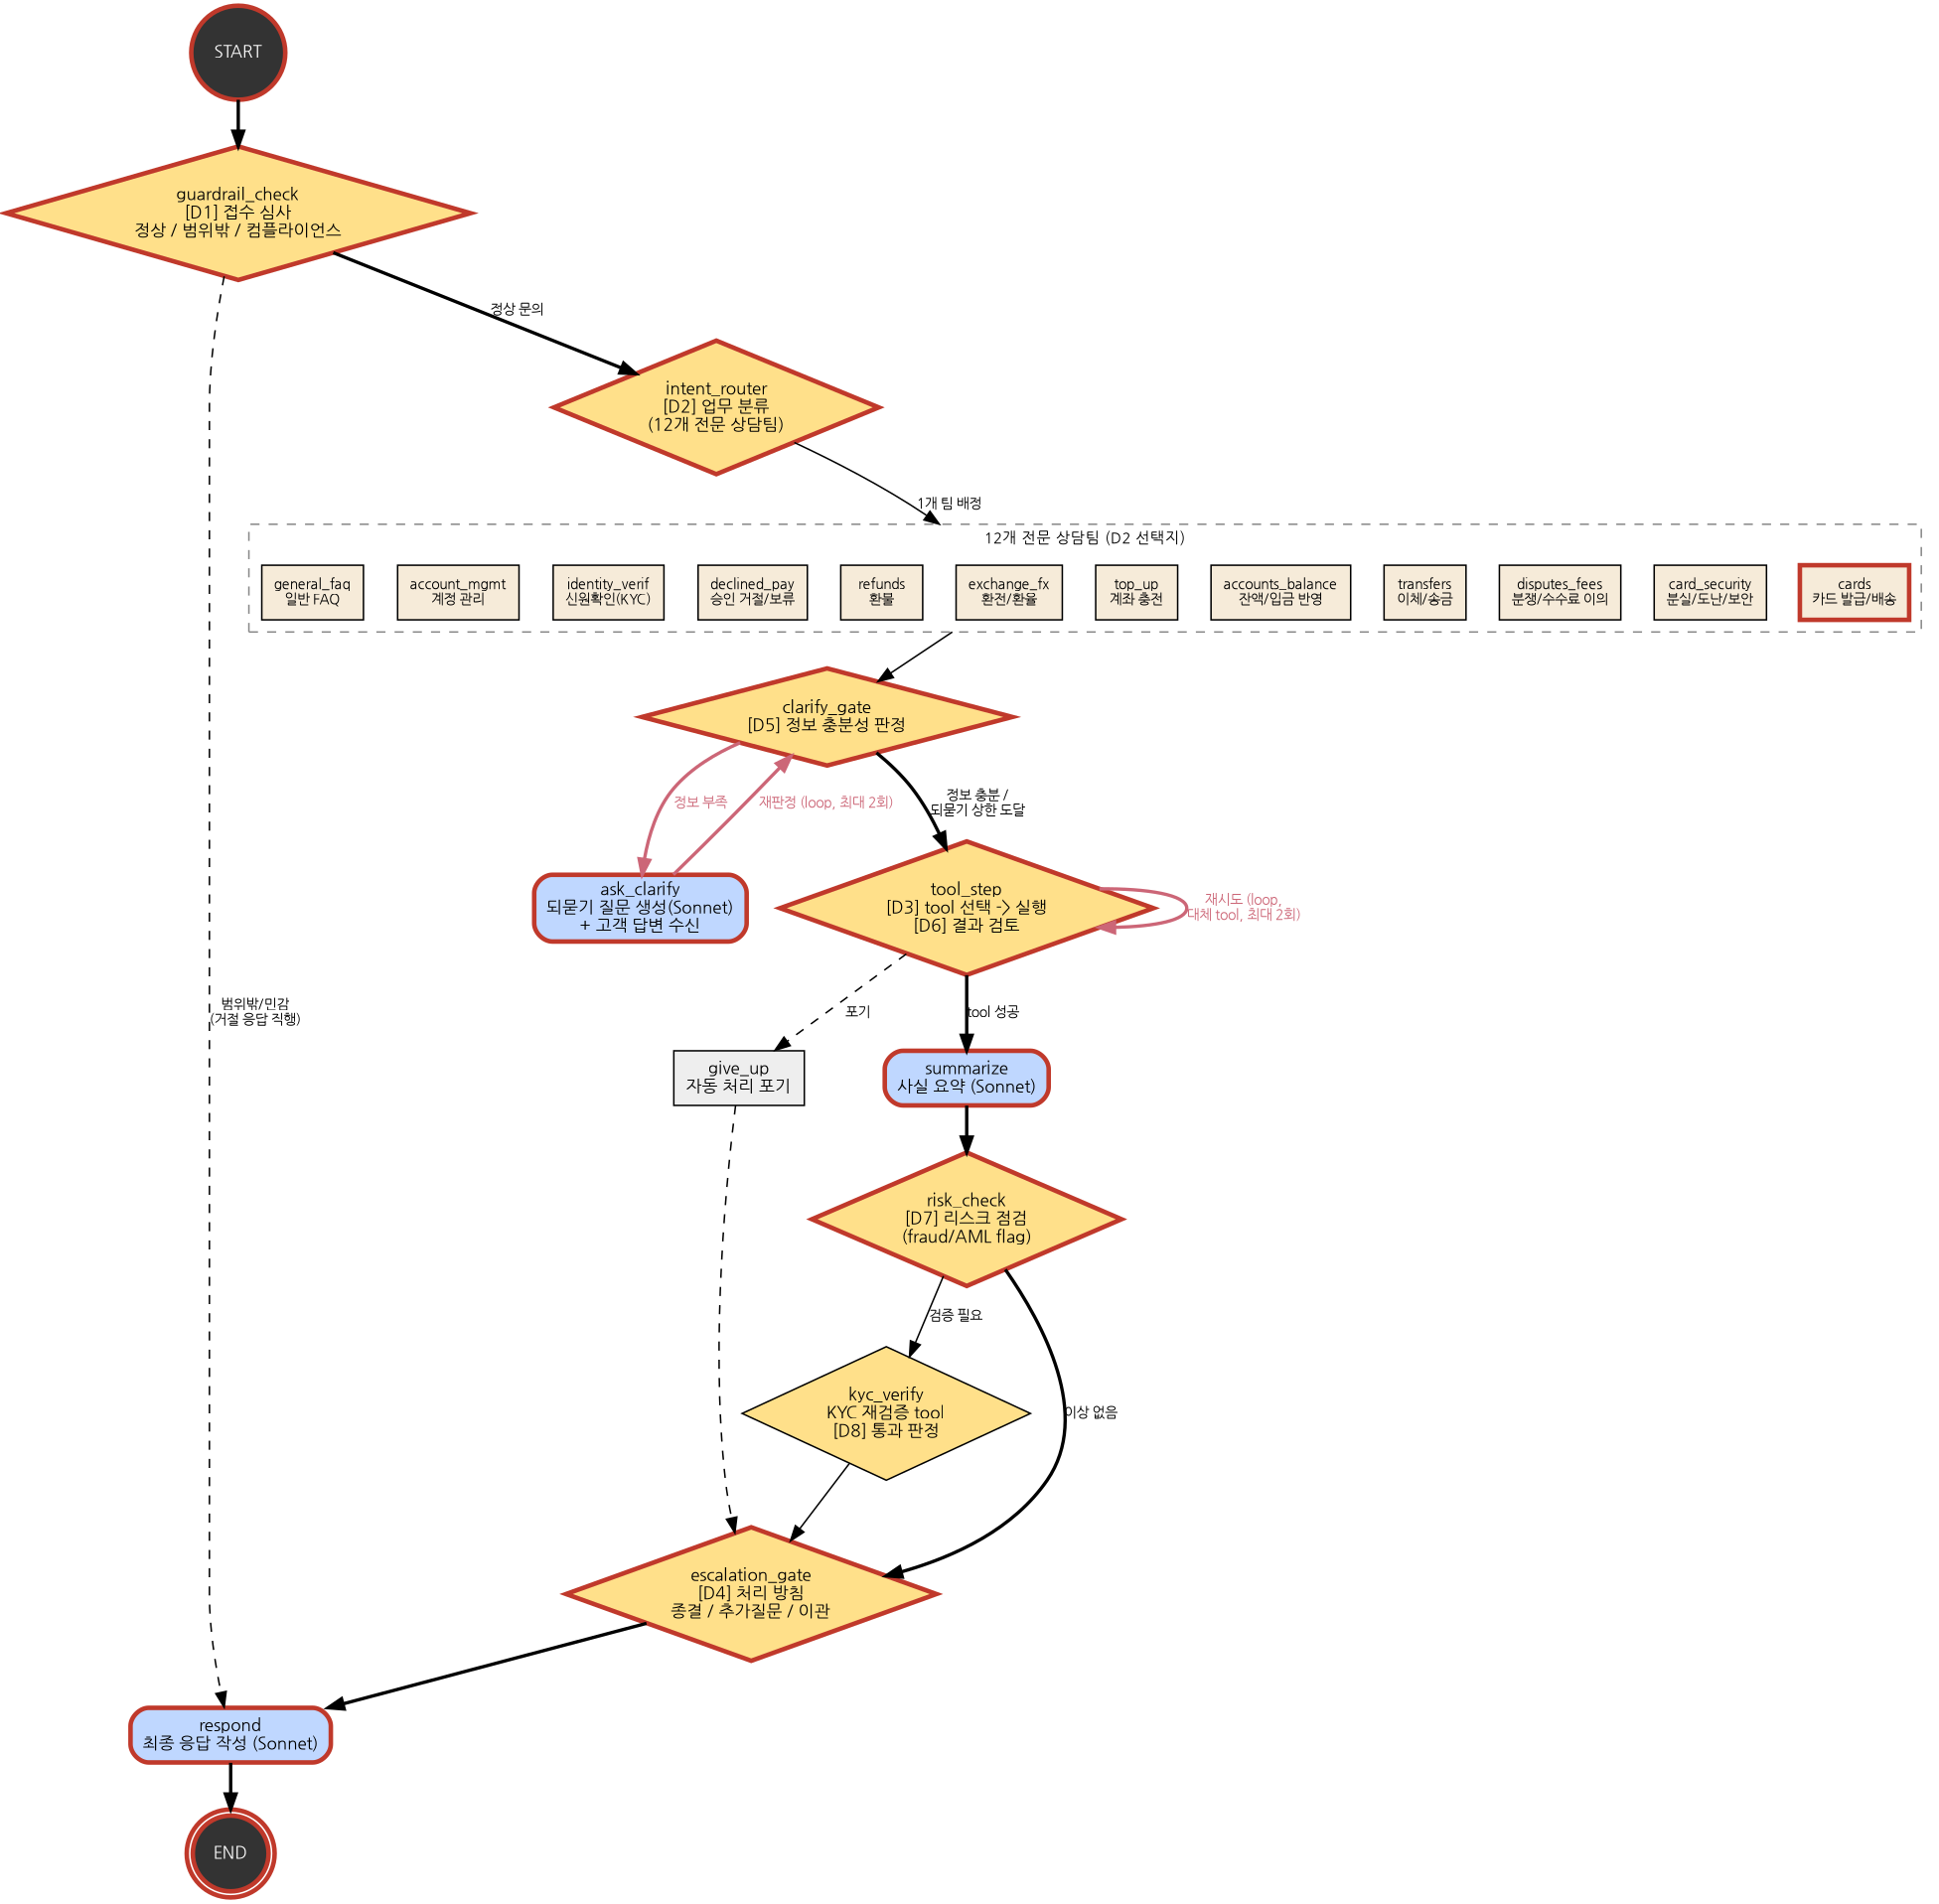

In [2]:
W.draw_graph(highlight=W.SCENARIO_PATHS[1], show_teams=True, width=760)

## ① Haiku 4.5가 판단하는 agent로 실행

각 STEP에서 어떤 노드가 어떤 판정(label)을 몇 ms에 내리는지, 되묻는 질문과 고객 답변, 최종 응답까지 그대로 출력됩니다. **판정 한 번마다 600ms 이상** 걸리는 것을 눈여겨보세요.

In [3]:
res_haiku = W.run_verbose(graphs["Haiku"], sc["question"], sc["script"], "Haiku")


[Haiku] 고객: 카드가 안 긁히는데 어떻게 해야 하나요?



STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (876ms)



STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> cards   (559ms)



STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> need_clarification   (654ms)



STEP 4 ▶ ask_clarify — 되묻기: Sonnet이 질문 생성 -> 고객 답변 수신
      생성(sonnet-4-5)   (1,759ms)
      상담 agent: 어떤 카드가 안 되시나요? 체크카드인가요, 신용카드인가요? 카드 마지막 4자리 번호를 알려주시겠어요?
      고객: 어제부터 오프라인 매장 단말기에서만 승인이 거절돼요. 관련 정보: Visa 체크카드(끝자리 7712), 마지막 시도 2026-10-27 TechMart 강남점, 금액 45,000원입니다.



STEP 5 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (523ms)



STEP 6 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> card_troubleshoot   (554ms)
      tool 실행: card_troubleshoot   (0.0ms)
      판정[D6] -> goal_met   (551ms)



STEP 7 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(sonnet-4-5)   (2,552ms)
      요약(첫 줄): Based on the tool result, here are the key resolution facts:



STEP 8 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> no_risk   (575ms)



STEP 9 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> clarify   (1,037ms)



STEP 10 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(sonnet-4-5)   (3,531ms)
      --- 최종 응답 ---
      고객님, 확인해주셔서 감사합니다.
      
      Visa 체크카드(끝자리 7712) 시스템 점검 결과, 카드 자체는 정상입니다. 
      
      오프라인 매장에서만 승인이 거절되는 경우, 다음을 확인해주세요:
      
      1. **계좌 잔액**이 충분한지 확인
      2. **일일 결제 한도** 초과 여부 확인
      3. 카드 **자기띠 손상** 가능성 - 다른 매장에서도 시도해보세요
      
      만약 다른 매장에서도 계속 거절된다면, 카드 재발급이 필요할 수 있습니다. 
      
      추가로 도움이 필요하시면 말씀해주세요!

>>> [Haiku] 결정 8회 합계 5,329ms | 생성 7,842ms | e2e 13,181ms


## ② strands-decider(E4B) 판단으로 실행

같은 그래프, 같은 질문입니다. 판정이 LLM 왕복 없이 로컬 서버의 forward pass 1회로 끝나고 **confidence**가 함께 찍히는 점이 다릅니다.

In [4]:
res_strands = W.run_verbose(graphs["StrandsDecider"], sc["question"], sc["script"], "StrandsDecider")


[StrandsDecider] 고객: 카드가 안 긁히는데 어떻게 해야 하나요?

STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (172ms, confidence 0.907)



STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> declined_pay   (155ms, confidence 0.466)

STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> need_clarification   (154ms, confidence 0.761)



STEP 4 ▶ ask_clarify — 되묻기: Sonnet이 질문 생성 -> 고객 답변 수신
      생성(sonnet-4-5)   (1,659ms)
      상담 agent: 어떤 카드가 안 되시나요? 체크카드인지 신용카드인지, 그리고 카드 마지막 4자리 번호를 알려주시겠어요?
      고객: 어제부터 오프라인 매장 단말기에서만 승인이 거절돼요. 관련 정보: Visa 체크카드(끝자리 7712), 마지막 시도 2026-10-27 TechMart 강남점, 금액 45,000원입니다.

STEP 5 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (156ms, confidence 0.648)



STEP 6 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> check_payment_status   (157ms, confidence 0.045)
      tool 실행: check_payment_status   (0.0ms)
      판정[D6] -> goal_met   (158ms, confidence 0.525)



STEP 7 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(sonnet-4-5)   (2,497ms)
      요약(첫 줄): Based on the tool result, here are the key resolution facts:

STEP 8 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> no_risk   (154ms, confidence 0.910)



STEP 9 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> resolve   (153ms, confidence 0.258)



STEP 10 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(sonnet-4-5)   (4,308ms)
      --- 최종 응답 ---
      고객님, 확인 결과 해당 카드(Visa 체크카드 끝자리 7712)는 시스템상 정상 상태입니다.
      
      오프라인 매장에서만 승인이 거절되는 경우, 다음을 확인해 주세요:
      
      1. **카드 마그네틱 손상**: 카드를 여러 번 긁어보시고, IC칩 삽입 방식도 시도해 주세요
      2. **계좌 잔액**: 체크카드 연결 계좌의 출금 가능 잔액을 확인해 주세요
      3. **1일 한도**: 당일 사용 금액이 설정된 한도를 초과했는지 확인해 주세요
      
      문제가 계속되면 가까운 지점에서 카드 재발급을 받으시거나, 고객센터(1588-XXXX)로 연락하시면 자세한 거래 내역을 확인해 드리겠습니다.
      
      참조번호: REF-ws-StrandsDecider-285716

>>> [StrandsDecider] 결정 8회 합계 1,259ms | 생성 8,464ms | e2e 9,732ms


## ③ 수행시간 비교

생성(Sonnet) 시간은 양쪽이 비슷하고, **판단 계층의 시간이 통째로 사라지는 것**이 핵심입니다.

In [5]:
W.compare(res_haiku, res_strands)

| 지표 | Haiku | StrandsDecider | 배수(Haiku/StrandsDecider) |
|---|---:|---:|---:|
| 결정 횟수 | 8 | 8 | |
| **결정 latency 합계** | **5,329ms** | **1,259ms** | **4.2x** |
| 생성(LLM) latency | 7,842ms | 8,464ms | **0.9x** |
| e2e | 13,181ms | 9,732ms | **1.4x** |

**결정 계층 속도 차이: 4.2x** (e2e 단축 3,449ms)

**결정별 latency**

| 노드 | 결정 | Haiku | StrandsDecider | 배수 | 판정 label |
|---|---|---:|---:|---:|---|
| guardrail_check | D1 | 876ms | 172ms | **5.1x** | in_scope (동일) |
| intent_router | D2 | 559ms | 155ms | **3.6x** | Haiku=cards / StrandsDecider=declined_pay |
| clarify_gate | D5 | 654ms | 154ms | **4.3x** | need_clarification (동일) |
| clarify_gate | D5 | 523ms | 156ms | **3.4x** | info_sufficient (동일) |
| tool_select | D3 | 554ms | 157ms | **3.5x** | Haiku=card_troubleshoot / StrandsDecider=check_payment_status |
| tool_review | D6 | 551ms | 158ms | **3.5x** | goal_met (동일) |
| risk_check | D7 | 575ms | 154ms | **3.7x** | no_risk (동일) |
| escalation_gate | D4 | 1,037ms | 153ms | **6.8x** | Haiku=clarify / StrandsDecider=resolve |

**관찰 포인트**
- 되묻기 loop 때문에 D5가 두 번 실행됩니다 — loop가 돌수록 판단 횟수가 늘고, 판단이 느린 backend일수록 누적 격차가 커집니다.
- 두 arm의 판정 label이 같은지 비교해 보세요(비교표 우측). label이 같다면 이 대화에서는 품질 손실 없이 속도만 얻은 것입니다.
- 다음: `[KR]_03_scenario2_retry.ipynb` — tool이 실패했을 때 agent가 스스로 복구하는 loop.